# ゼロから作る Deep Learning ❹ 輪読会
## 第1章「バンディット問題」 ― 1.1 〜 1.3

**はじめに**：

これまでのシリーズでは、データから予測のための規則を学んだり、その学習を支える自動微分を実装したりしてきました。今回は、**自分で行動し、その結果から次の行動を改善する**「強化学習」を学びます。

最初の題材は、当たりやすさが分からない複数のスロットマシンから、どれを選ぶかというバンディット問題です。「今よさそうな台を選ぶ」ことと「まだよく知らない台を試す」ことを、どう両立すればよいでしょうか。

**今回の目標**：

- 教師あり学習・教師なし学習・強化学習の違いを、与えられる情報から説明します。
- 行動・報酬・行動価値を区別し、報酬の期待値を計算します。
- 観測した報酬から価値を推定し、平均値を1回ずつ更新します。
- 活用と探索の違いを理解し、ε-greedy法の行動選択を確かめます。

> **Table of contents**
>
> 1. 1.1：機械学習の分類と強化学習
> 2. 1.2：バンディット問題
> 3. 1.3：バンディットアルゴリズム
> 4. 振り返りと確認問題

節の対応は[出版社の目次](https://www.oreilly.co.jp/books/9784873119755/)を参照しています。解説と小さな実験は輪読用に構成したものです。

平均値の実装は [`ch01/avg.py`](../ch01/avg.py)、行動選択のコードは [`ch01/bandit.py`](../ch01/bandit.py) に対応します。環境とエージェントをクラスとして組み合わせる実装は、次の1.4で扱います。

## ライブラリの読み込み

必要なライブラリは NumPy と Matplotlib です。セルを上から順に実行してください。他のノートブックの実行結果やデータファイルは使いません。

このリポジトリのルートで、次のコマンドから JupyterLab を起動できます。

```bash
uv run --extra notebooks jupyter lab my_notebooks
```

乱数を使う実験ではシードを固定し、同じ結果を再現できるようにします。グラフ内のラベルは、日本語フォントがなくても表示できるよう英語で記します。

[ch01/avg.py](../ch01/avg.py) / [ch01/bandit.py](../ch01/bandit.py)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
print("NumPy version:", np.__version__)

NumPy version: 1.23.5


---
# 1.1：機械学習の分類と強化学習

学習方法を比べるときは、「何を入力として受け取り、何を手がかりに改善するか」に注目すると分かりやすいです。

| 学習の種類 | 学習に使う情報 | 目指すこと | 例 |
|---|---|---|---|
| 教師あり学習 | 入力と、それに対応する正解 | 未知の入力に対する正解を予測する | 画像から動物の種類を予測する |
| 教師なし学習 | 正解ラベルを付けていないデータ | データの構造や特徴を見つける | 似た購買傾向の顧客をまとめる |
| 強化学習 | 行動した結果として得た観測と報酬 | 得られる報酬の合計の期待値を大きくする | 試行錯誤しながらゲームの戦略を学ぶ |

これらは代表的な分類であり、実際には組み合わせて利用する場合もあります。

## 1.1.1 教師あり学習

教師あり学習では、入力 $x$ と正解 $y$ の組を用意します。たとえば、住宅の面積を入力にして価格を予測する場合、過去の「面積と価格」のデータが教師になります。

$$
\text{入力 } x \;\longrightarrow\; \text{モデルの予測 } \hat{y}
\;\longrightarrow\; \text{正解 } y \text{ とのずれを小さくする}
$$

価格のような連続値を予測する問題は**回帰**、犬・猫のようなカテゴリを予測する問題は**分類**と呼びます。

ここでのポイントは、学習時に「その入力に対して望ましい出力」が与えられることです。モデルは損失関数によって予測と正解のずれを測り、パラメータを調整します。

## 1.1.2 教師なし学習

教師なし学習では、入力データに対応する正解ラベルを用意せず、データ自身の構造を調べます。

- **クラスタリング**：似たデータをグループにまとめます。
- **次元削減**：多くの特徴を持つデータを、特徴をなるべく保って少ない次元で表します。

たとえば顧客を購入傾向からグループに分ける場合、「顧客Aはグループ1」という正解を先に与えるわけではありません。データ間の似ている度合いを手がかりにします。

> 「教師なし」は「評価基準が何もない」という意味ではありません。データの再構成誤差など、目的に応じた基準を使って学習します。

## 1.1.3 強化学習

強化学習では、行動を決める主体を**エージェント**、その行動を受けて結果を返す対象を**環境**と呼びます。

1. エージェントが、得られている情報をもとに行動を選びます。
2. 環境が行動を受け取り、報酬や次の観測を返します。
3. エージェントが、その経験をもとに行動の選び方を改善します。

**報酬**は行動の結果を評価する数値であり、「正解の行動そのもの」ではありません。たとえば、スロットで外れたと分かっても、代わりにどの台を選ぶべきだったかまでは分かりません。

また、一般の強化学習では、ある行動の効果が後から現れる場合があります。目先の報酬だけで判断せず、その先まで含めて得られる報酬を考える必要があります。

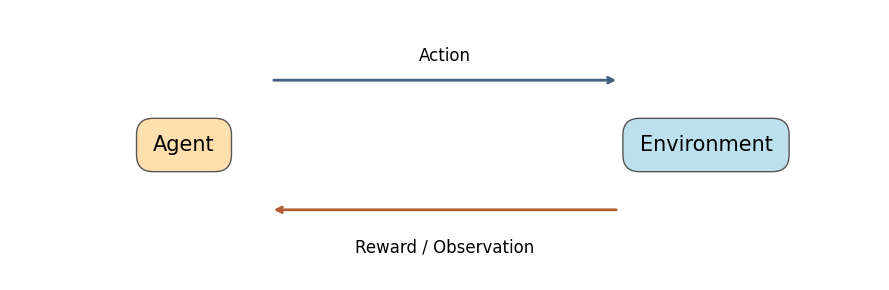

In [2]:
# エージェントと環境のやりとりを図にする
fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

for x, label, color in [(0.2, "Agent", "#ffe0ad"),
                        (0.8, "Environment", "#bde0ee")]:
    ax.text(x, 0.5, label, ha="center", va="center", fontsize=15,
            bbox=dict(boxstyle="round,pad=0.8", fc=color, ec="#555555"))

ax.annotate("", xy=(0.7, 0.74), xytext=(0.3, 0.74),
            arrowprops=dict(arrowstyle="->", lw=2, color="#406080"))
ax.text(0.5, 0.81, "Action", ha="center", fontsize=12)
ax.annotate("", xy=(0.3, 0.26), xytext=(0.7, 0.26),
            arrowprops=dict(arrowstyle="->", lw=2, color="#b05b32"))
ax.text(0.5, 0.10, "Reward / Observation", ha="center", fontsize=12)
ax.set(xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
plt.show()

図のループを繰り返す中で、エージェントが集める経験も変化します。学習用のデータを、自分の行動によって集めていることになります。

今回のバンディット問題では、環境の状態が行動によって変化する仕組みはいったん省き、**行動と報酬の関係**に集中します。

> **1.1のまとめ**
>
> - 教師あり学習は正解との対応、教師なし学習はデータの構造を手がかりにします。
> - 強化学習では、エージェントが環境とやりとりして経験を集めます。
> - 報酬は結果の評価であり、正解の行動を直接教えるものではありません。

---
# 1.2：バンディット問題

## 1.2.1 バンディット問題とは

目の前に複数のスロットマシンがあり、1回ごとに1台を選んで遊べるとします。台ごとに当たりや報酬の出方は異なりますが、その仕組みをプレイヤーは知りません。

限られた試行回数の中で、得られる報酬の合計をできるだけ大きくしたいと考えます。これが、<strong>多腕バンディット問題（multi-armed bandit problem）</strong>の基本的な設定です。スロットのレバーに由来して、選択肢を「腕（arm）」とも呼びます。

| 強化学習の用語 | この例での意味 |
|---|---|
| エージェント | 台を選ぶプレイヤー |
| 環境 | スロットマシン群と、その報酬を出す仕組み |
| 行動 $a$ | どの台を選ぶか |
| 報酬 $R$ | 選んだ台から得た点数 |

ここでは、各台の報酬の確率分布が時間で変わらない**定常な問題**を考えます。また、報酬は選んだ台についてだけ観測できます。

## 1.2.2 良いスロットマシンとは

たまたま1回大当たりした台が、長い目で見てもよい台とは限りません。そこで、報酬の**期待値**を基準にします。

離散的な報酬の場合、期待値は「報酬の値 × その値が出る確率」の合計です。

$$
\mathbb{E}[R] = \sum_r r\,P(R=r)
$$

次の3台を考えてみましょう。外れの報酬はすべて0、試行ごとの費用は同じとします。

| 台 | 当たる確率 | 当たったときの報酬 | 報酬の期待値 |
|---|---:|---:|---:|
| A | 0.25 | 4 | $0.25\times4=1.0$ |
| B | 0.60 | 1 | $0.60\times1=0.6$ |
| C | 0.10 | 15 | $0.10\times15=1.5$ |

最も当たりやすい台はBですが、報酬の期待値が最大の台はCです。**当たりやすさと、報酬の期待値が大きいことは、一般には同じではありません**。

ここに示した確率は、説明のために用意した環境側の情報です。実際のプレイヤーは、得た報酬からよさを推測する必要があります。

台 A: 報酬の期待値 = 1.00
台 B: 報酬の期待値 = 0.60
台 C: 報酬の期待値 = 1.50
期待値が最大の台: C


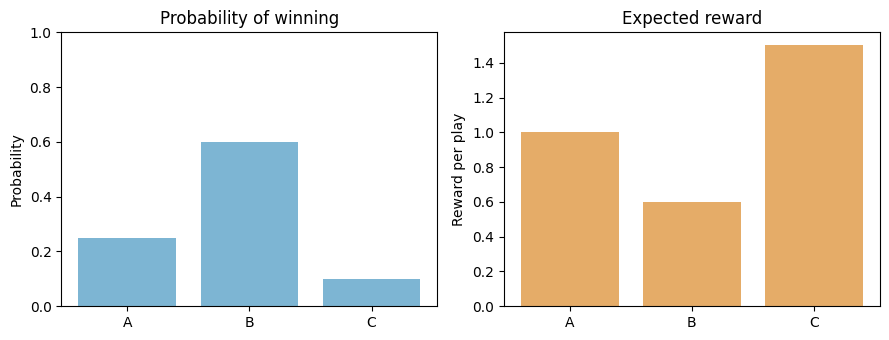

In [3]:
names = np.array(["A", "B", "C"])
win_probabilities = np.array([0.25, 0.60, 0.10])
payouts = np.array([4, 1, 15])
expected_rewards = win_probabilities * payouts

for name, value in zip(names, expected_rewards):
    print(f"台 {name}: 報酬の期待値 = {value:.2f}")
print("期待値が最大の台:", names[np.argmax(expected_rewards)])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(names, win_probabilities, color="#7db5d3")
axes[0].set(title="Probability of winning", ylabel="Probability", ylim=(0, 1))
axes[1].bar(names, expected_rewards, color="#e5ac68")
axes[1].set(title="Expected reward", ylabel="Reward per play")
plt.tight_layout()
plt.show()

グラフの左と右で、最も高い棒が異なる点に注目してください。強化学習でどの行動が望ましいかを考えるには、どのような報酬を定義したかが重要になります。

以降のバンディットの例では、書籍の実装に合わせて**当たりは1、外れは0**にそろえます。この場合に限れば、報酬の期待値は当たる確率と等しいです。

$$
\mathbb{E}[R] = 1\times p + 0\times(1-p)=p
$$

## 1.2.3 数式を使って表す

行動を $A$、報酬を $R$ という確率変数で表します。行動 $a$ を選んだときの報酬の分布を $p(r\mid a)$ と書きます。

$$
p(r\mid a)=P(R=r\mid A=a)
$$

縦棒 $\mid$ は「〜という条件のもとで」を表します。その行動のよさを表す**行動価値**は、次の期待値で定義します。

$$
q(a)=\mathbb{E}[R\mid A=a]
    =\sum_r r\,p(r\mid a)
$$

| 記号 | 意味 |
|---|---|
| $a$ | 具体的な行動（台の番号など） |
| $r$ | 具体的な報酬の値 |
| $p(r\mid a)$ | 行動 $a$ を選んだときに報酬 $r$ が出る確率 |
| $q(a)$ | 環境が持つ、行動 $a$ の真の価値 |
| $Q(a)$ | 観測データから求めた、行動 $a$ の価値の推定値 |

$q(a)$ が分かっていれば、最大の価値を持つ行動を選べばよいです。

$$
a^*\in\operatorname*{arg\,max}_a q(a)
$$

`max` は最大の**値**、`argmax` はその値を与える<strong>引数（ここでは行動）</strong>を求めます。最大値が複数ある場合は、その中のどれを選んでもかまいません。

In [4]:
# 各行動について、報酬0と報酬1の確率を並べる
reward_values = np.array([0, 1])
reward_probabilities = np.array([
    [0.8, 0.2],  # 行動0: 80%で報酬0、20%で報酬1
    [0.5, 0.5],  # 行動1
    [0.2, 0.8],  # 行動2
])

# それぞれの行の確率の和が1であることを確認
assert np.allclose(reward_probabilities.sum(axis=1), 1.0)
true_values = (reward_probabilities * reward_values).sum(axis=1)

print("真の行動価値 q(a):", true_values)
print("価値の最大値:", np.max(true_values))
print("価値が最大の行動:", np.argmax(true_values))

真の行動価値 q(a): [0.2 0.5 0.8]
価値の最大値: 0.8
価値が最大の行動: 2


この例では $q(0)=0.2$、$q(1)=0.5$、$q(2)=0.8$ です。真の価値を知っているなら、行動2を選ぶのがよいです。

ただし、プレイヤーに `true_values` を渡してしまうと、未知の台を試すという問題がなくなります。次の節では、**真の価値を使わず、観測した報酬から $Q(a)$ を求めます**。

> **1.2のまとめ**
>
> - バンディット問題では、複数の選択肢から行動を選び、選んだ行動の報酬だけを得ます。
> - 行動のよさは、1回の結果ではなく報酬の期待値 $q(a)$ で考えます。
> - 当たり1・外れ0なら、行動価値は当たる確率と一致します。
> - 真の価値 $q(a)$ と、その推定値 $Q(a)$ を区別します。

---
# 1.3：バンディットアルゴリズム

これから必要になるのは、次の2つの仕組みです。

1. **価値の推定**：得た報酬から、それぞれの台のよさを推測します。
2. **行動の選択**：現在の推定を使って、次にどの台を選ぶか決めます。

## 1.3.1 価値の推定方法

ある行動 $a$ を $n$ 回選び、そのときの報酬を $R_1,\ldots,R_n$ とします。期待値の代わりに、観測した報酬の**標本平均**を使います。

$$
Q_n(a)=\frac{R_1+R_2+\cdots+R_n}{n}
$$

ここでは、$Q_n(a)$ を「行動 $a$ の報酬を **$n$ 個観測した後**の推定値」と定義します。$n$ は全体の試行回数ではなく、その行動を選んだ回数です。

当たり1・外れ0の場合、標本平均は「当たった回数 ÷ 選んだ回数」になります。

[ch01/avg.py](../ch01/avg.py)

In [5]:
# 台ごとに得られた報酬の記録（説明用の小さなデータ）
observed_rewards = {
    0: [1, 0, 1, 1],
    1: [0, 1],
    2: [1, 1, 0],
}

for action, rewards in observed_rewards.items():
    estimate = sum(rewards) / len(rewards)
    print(f"行動{action}: 回数={len(rewards)}, 報酬={rewards}, Q={estimate:.3f}")

行動0: 回数=4, 報酬=[1, 0, 1, 1], Q=0.750
行動1: 回数=2, 報酬=[0, 1], Q=0.500
行動2: 回数=3, 報酬=[1, 1, 0], Q=0.667


行動0の推定値は $3/4=0.75$、行動1は $1/2=0.5$、行動2は $2/3\approx0.667$ となります。台ごとに分母が違う点を確認してください。

同じ分布から独立に報酬が得られる今回の設定では、観測回数を増やすと標本平均は真の期待値に近づいていきます。ただし、**誤差が毎回必ず小さくなるわけではありません**。少数の観測から得た値には、特に大きなばらつきがあります。

### 追加検証：試行回数と推定値のばらつき

当たる確率が $0.7$ の台を繰り返し選び、標本平均の変化を見ます。同じ確率の台でも、得られる報酬列が違えば推定の経路は変わります。

この実験では、環境を作るために真の確率を指定します。推定値の計算に使う情報は、生成された報酬だけです。

seed=0: 2000回後の推定値 = 0.6970
seed=1: 2000回後の推定値 = 0.7040
seed=2: 2000回後の推定値 = 0.7030


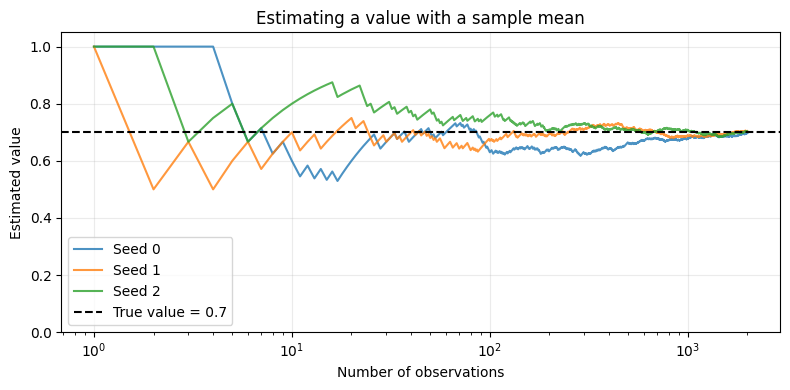

In [6]:
probability = 0.7
sample_count = 2000
sample_numbers = np.arange(1, sample_count + 1)

fig, ax = plt.subplots(figsize=(8, 4))
for seed in range(3):
    rng = np.random.default_rng(seed)
    rewards = (rng.random(sample_count) < probability).astype(int)
    estimates = np.cumsum(rewards) / sample_numbers
    ax.plot(sample_numbers, estimates, label=f"Seed {seed}", alpha=0.8)
    print(f"seed={seed}: {sample_count}回後の推定値 = {estimates[-1]:.4f}")

ax.axhline(probability, color="black", linestyle="--", label="True value = 0.7")
ax.set(xscale="log", xlabel="Number of observations", ylabel="Estimated value",
       title="Estimating a value with a sample mean", ylim=(0, 1.05))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

横軸は、少ない試行回数の部分も見やすいよう対数スケールにしています。初めは大きく揺れ、回数が増えるとおおむね $0.7$ の周囲に集まる様子を確認できます。

> 未選択の台では、まだ平均を計算できません。実装で $Q(a)=0$ と初期化する場合、それは仮の値であり、「真の価値が0だと分かった」という意味ではありません。

## 1.3.2 平均値を求める実装

まず、報酬をすべてリストに保存して、毎回平均を計算します。ここでは [`ch01/avg.py`](../ch01/avg.py) と同様に、0以上1未満の一様乱数を報酬として使います。

平均の求め方自体は、報酬が0/1でも連続値でも同じです。

[ch01/avg.py](../ch01/avg.py)

In [7]:
# 素朴な実装：これまでの報酬を保存し、その都度合計する
np.random.seed(0)
rewards = []
naive_means = []

for n in range(1, 11):
    reward = np.random.rand()
    rewards.append(reward)
    Q = sum(rewards) / n
    naive_means.append(Q)
    print(f"n={n:2d}, reward={reward:.4f}, Q={Q:.6f}")

n= 1, reward=0.5488, Q=0.548814
n= 2, reward=0.7152, Q=0.632001
n= 3, reward=0.6028, Q=0.622255
n= 4, reward=0.5449, Q=0.602912
n= 5, reward=0.4237, Q=0.567061
n= 6, reward=0.6459, Q=0.580200
n= 7, reward=0.4376, Q=0.559827
n= 8, reward=0.8918, Q=0.601320
n= 9, reward=0.9637, Q=0.641580
n=10, reward=0.3834, Q=0.615766


### 過去の平均から、新しい平均を作る

報酬を $n-1$ 個観測した時点の平均を $Q_{n-1}$ とします。新しい報酬 $R_n$ を1つ得た後の平均は、次のように変形できます。

$$
\begin{aligned}
Q_n
&=\frac{R_1+\cdots+R_{n-1}+R_n}{n}\\[3pt]
&=\frac{(n-1)Q_{n-1}+R_n}{n}\\[3pt]
&=Q_{n-1}+\frac{1}{n}\left(R_n-Q_{n-1}\right)
\end{aligned}
$$

つまり、すべての報酬を覚えていなくても、**前の平均・新しい報酬・観測回数**があれば更新できます。

$$
\underbrace{\text{新しい推定値}}_{Q_n}
=\underbrace{\text{古い推定値}}_{Q_{n-1}}
+\underbrace{\frac{1}{n}}_{\text{更新の大きさ}}
\underbrace{\left(R_n-Q_{n-1}\right)}_{\text{予測とのずれ}}
$$

- 新しい報酬が現在の推定値より大きければ、推定値は上がります。
- 小さければ、推定値は下がります。
- 観測回数が増えると、新しい報酬1個の影響は小さくなります。

初期値を $Q_0=0$ とすると、最初は $Q_1=0+(R_1-0)/1=R_1$ となります。分母に0を使わないよう、観測回数は1から数えます。

[ch01/avg.py](../ch01/avg.py)

In [8]:
# 逐次的な実装：平均Qと観測回数nだけで更新する
np.random.seed(0)  # 素朴な実装と同じ報酬列を生成する
Q = 0.0
incremental_means = []  # 比較表示のための保存。平均の更新自体には不要

for n in range(1, 11):
    reward = np.random.rand()
    Q += (reward - Q) / n
    incremental_means.append(Q)
    print(f"n={n:2d}, reward={reward:.4f}, Q={Q:.6f}")

n= 1, reward=0.5488, Q=0.548814
n= 2, reward=0.7152, Q=0.632001
n= 3, reward=0.6028, Q=0.622255
n= 4, reward=0.5449, Q=0.602912
n= 5, reward=0.4237, Q=0.567061
n= 6, reward=0.6459, Q=0.580200
n= 7, reward=0.4376, Q=0.559827
n= 8, reward=0.8918, Q=0.601320
n= 9, reward=0.9637, Q=0.641580
n=10, reward=0.3834, Q=0.615766


### 2つの実装を照合する

乱数のシードを同じ値に戻してから実行したので、2つの実装には同じ順番で同じ報酬が入力されています。その各時点の平均を比べます。

数学的には同じ値ですが、浮動小数点の計算順序によってごく小さな差が出る場合があります。そのため、完全一致を調べる `==` ではなく、十分近いことを調べる `np.allclose` を使います。

In [9]:
naive_means = np.array(naive_means)
incremental_means = np.array(incremental_means)

print("n   素朴な実装   逐次的な実装")
for n, (naive, incremental) in enumerate(zip(naive_means, incremental_means), start=1):
    print(f"{n:2d}  {naive:.8f}   {incremental:.8f}")

max_difference = np.max(np.abs(naive_means - incremental_means))
print("差の絶対値の最大:", max_difference)
assert np.allclose(naive_means, incremental_means)
print("すべての時点で、2つの平均が数値誤差の範囲で一致した")

n   素朴な実装   逐次的な実装
 1  0.54881350   0.54881350
 2  0.63200144   0.63200144
 3  0.62225542   0.62225542
 4  0.60291236   0.60291236
 5  0.56706085   0.56706085
 6  0.58019972   0.58019972
 7  0.55982651   0.55982651
 8  0.60131982   0.60131982
 9  0.64158015   0.64158015
10  0.61576628   0.61576628
差の絶対値の最大: 1.1102230246251565e-16
すべての時点で、2つの平均が数値誤差の範囲で一致した


素朴な実装では、$n$ 個の報酬を保存し、更新のたびにそれらを合計します。逐次的な実装では、保存する値も1回の更新で行う計算も一定で済みます。

| 方法 | 平均の計算に保持する情報 | $n$ 回目の更新に必要な計算量 |
|---|---|---|
| 報酬リストを毎回合計 | 報酬 $n$ 個 | $O(n)$ |
| 逐次更新 | 現在の平均と観測回数 | $O(1)$ |

なお、累積和と回数を保持して割り算する方法も $O(1)$ で更新できます。ここで逐次更新式に注目するのは、「古い推定値に、予測とのずれを使った補正を加える」という形が、この先の強化学習でも繰り返し登場するためです。

### 複数の行動では、行動ごとに平均と回数を持つ

行動が複数ある場合は、`Qs[action]` に推定値、`ns[action]` にその行動の観測回数を保存します。

選んだ行動だけの回数を1増やしてから、対応する平均を更新します。選ばなかった行動の報酬は分からないので、その推定値は変更しません。

[ch01/bandit.py](../ch01/bandit.py)

In [10]:
# 説明用に、行動と報酬の履歴を固定する
history = [(0, 1), (1, 0), (0, 0), (2, 1), (1, 1), (0, 1)]
Qs = np.zeros(3)
ns = np.zeros(3, dtype=int)

for step, (action, reward) in enumerate(history, start=1):
    ns[action] += 1
    Qs[action] += (reward - Qs[action]) / ns[action]
    print(f"step={step}, action={action}, reward={reward}, "
          f"ns={ns}, Qs={np.round(Qs, 3)}")

# 行動0は6ステップ中3回選ばれ、報酬の合計は2
assert np.array_equal(ns, [3, 2, 1])
assert np.allclose(Qs, [2 / 3, 1 / 2, 1.0])

step=1, action=0, reward=1, ns=[1 0 0], Qs=[1. 0. 0.]
step=2, action=1, reward=0, ns=[1 1 0], Qs=[1. 0. 0.]
step=3, action=0, reward=0, ns=[2 1 0], Qs=[0.5 0.  0. ]
step=4, action=2, reward=1, ns=[2 1 1], Qs=[0.5 0.  1. ]
step=5, action=1, reward=1, ns=[2 2 1], Qs=[0.5 0.5 1. ]
step=6, action=0, reward=1, ns=[3 2 1], Qs=[0.667 0.5   1.   ]


最後の行で、行動0の平均は $2/3$ になります。全体では6回遊んでいますが、分母を6にしてはいけません。

一方、行動2の推定値は1ですが、これは1回選んで1回当たった結果にすぎません。観測回数が少ない推定値をそのまま信じてよいか、という問題が次の「行動の選択」につながります。

## 1.3.3 プレイヤーの戦略

### greedy法：今の推定値が最大の行動を選ぶ

現在もっともよいと思われる行動を選ぶ方法を <strong>greedy法（貪欲法）</strong>といいます。

$$
a=\operatorname*{arg\,max}_a Q(a)
$$

ここで使うのは、未知の真の価値 $q(a)$ ではなく、経験から得た推定値 $Q(a)$ です。

[ch01/bandit.py](../ch01/bandit.py)

In [11]:
estimated_values = np.array([0.8, 0.3, 0.4])
greedy_action = int(np.argmax(estimated_values))

print("現在の推定値 Q(a):", estimated_values)
print("greedy法が選ぶ行動:", greedy_action)
print("その推定値:", estimated_values[greedy_action])

# 同じ最大値が複数ある場合、np.argmaxは先頭のインデックスを返す
print("すべて未選択でQ=0の場合:", np.argmax(np.zeros(3)))

現在の推定値 Q(a): [0.8 0.3 0.4]
greedy法が選ぶ行動: 0
その推定値: 0.8
すべて未選択でQ=0の場合: 0


### 活用と探索のトレードオフ

greedy法の弱点は、誤った推定値をもとに同じ行動を選び続ける可能性があることです。たとえば、本当はよい台でも最初に外れると、推定値が低いまま選ばれなくなるかもしれません。選ばれなければ新しい経験が増えず、評価を修正する機会も得られません。

- **活用（exploitation）**：これまでの経験を使い、今よさそうな行動を選びます。
- **探索（exploration）**：ほかの行動も試し、よりよい行動を見つけるための情報を集めます。

活用を優先すると今の報酬を得やすい一方、よい選択肢を見逃すかもしれません。探索を優先すると情報は増えますが、価値が低い行動も選ぶことになります。この両立がバンディット問題の中心になります。

### ε-greedy法：ときどきランダムに選ぶ

$0\leq\varepsilon\leq1$ を探索の確率とし、次のように行動を選びます。

$$
A=\begin{cases}
\text{すべての行動から一様ランダムに選ぶ} & \text{確率 }\varepsilon\\
\operatorname*{arg\,max}_a Q(a) & \text{確率 }1-\varepsilon
\end{cases}
$$

- $\varepsilon=0$：毎回greedy法で選びます。
- $\varepsilon=1$：毎回一様ランダムに選びます。
- たとえば $\varepsilon=0.1$：10%の確率で探索し、90%の確率で活用します。

探索では、**現在のgreedy行動も含めたすべての行動**が候補になります。そのため、「探索した回数」と「greedy行動以外を選んだ回数」は同じではありません。

[ch01/bandit.py](../ch01/bandit.py)

In [12]:
def epsilon_greedy(Qs, epsilon, rng):
    """推定値Qsから行動を1つ選ぶ。0 <= epsilon <= 1を想定する。"""
    if rng.random() < epsilon:
        # 0以上、行動数未満の整数。greedy行動も候補に含まれる
        return int(rng.integers(len(Qs)))
    return int(np.argmax(Qs))


# rngは乱数を生成するオブジェクト。シードを指定すると結果を再現できる
rng = np.random.default_rng(0)
actions = [epsilon_greedy(estimated_values, 0.1, rng) for _ in range(20)]
print("ε=0.1で20回選んだ行動:", actions)

ε=0.1で20回選んだ行動: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0]


### 追加検証：各行動が選ばれる確率

行動数が $k$、greedy行動を1つに決める場合、各行動の選択確率は次のようになります。この実装では同値の場合も `np.argmax` が先頭を選びます。

$$
P(A=a)=
\begin{cases}
1-\varepsilon+\varepsilon/k & a\text{ がgreedy行動の場合}\\
\varepsilon/k & \text{それ以外}
\end{cases}
$$

今回の $k=3,\ \varepsilon=0.1$ なら、greedy行動は約 $0.9333$、残りの2つはそれぞれ約 $0.0333$ の確率で選ばれます。

次のセルでは、**推定値を固定したまま行動選択だけを繰り返します**。報酬を受け取って学習する実験ではなく、選択確率の確認です。

ε=0.0: 実測=[1. 0. 0.], 理論=[1. 0. 0.]
ε=0.1: 実測=[0.9347 0.0327 0.0327], 理論=[0.9333 0.0333 0.0333]
ε=1.0: 実測=[0.3339 0.3336 0.3325], 理論=[0.3333 0.3333 0.3333]


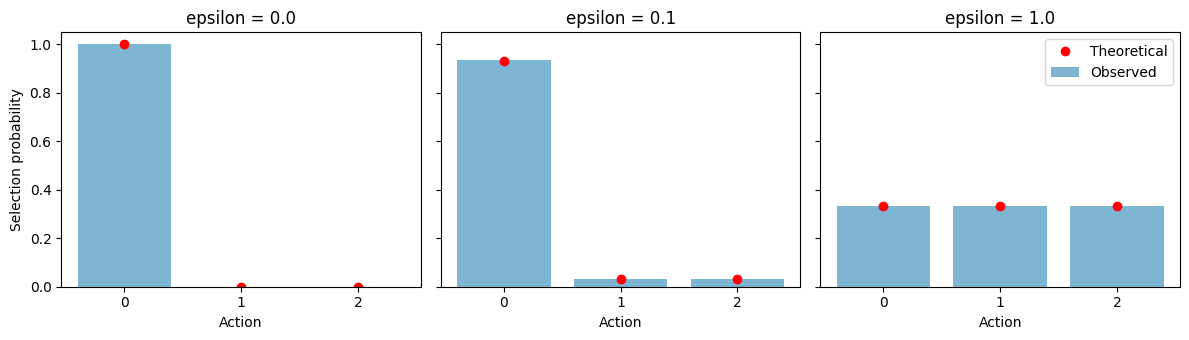

In [13]:
selection_count = 30000
fixed_Qs = np.array([0.8, 0.3, 0.4])
action_size = len(fixed_Qs)
epsilons = [0.0, 0.1, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
selection_results = {}

for ax, epsilon in zip(axes, epsilons):
    rng = np.random.default_rng(42)
    counts = np.zeros(action_size, dtype=int)
    for _ in range(selection_count):
        action = epsilon_greedy(fixed_Qs, epsilon, rng)
        counts[action] += 1
    frequencies = counts / selection_count

    theoretical = np.full(action_size, epsilon / action_size)
    theoretical[np.argmax(fixed_Qs)] += 1 - epsilon
    selection_results[epsilon] = (frequencies, theoretical)
    print(f"ε={epsilon:.1f}: 実測={np.round(frequencies, 4)}, "
          f"理論={np.round(theoretical, 4)}")

    ax.bar(np.arange(action_size), frequencies, color="#7db5d3", label="Observed")
    ax.plot(np.arange(action_size), theoretical, "ro", label="Theoretical")
    ax.set(title=f"epsilon = {epsilon}", xlabel="Action", xticks=np.arange(action_size),
           ylim=(0, 1.05))
axes[0].set_ylabel("Selection probability")
axes[-1].legend()
plt.tight_layout()
plt.show()

$\varepsilon=0$ では行動0だけ、$\varepsilon=1$ では3つがほぼ同じ割合で選ばれます。$\varepsilon=0.1$ の実測値は理論値の近くになりますが、有限回の試行なので完全には一致しません。

$\varepsilon$ を大きくすれば必ず報酬が増えるわけではありません。適した値は試行回数や台どうしの価値の差などによって変わります。また、正の $\varepsilon$ を固定すると、よい台を見つけた後も一定割合で探索を続けます。

> **1.3のまとめ**
>
> - 報酬の標本平均から、行動価値 $Q(a)$ を推定できます。
> - 平均は `Q += (reward - Q) / n` で逐次更新できます。
> - 複数の行動では、その行動を選んだ回数 `ns[action]` を分母にします。
> - greedy法は現在の推定を活用しますが、よい行動を見逃すことがあります。
> - ε-greedy法は、確率εで探索し、残りで活用します。

---
# 今回のまとめ

1. **1.1：学び方の違い** — 強化学習では、自分の行動で経験を集め、報酬を手がかりに行動を改善します。
2. **1.2：行動のよさを定義する** — 行動価値 $q(a)$ は報酬の期待値です。1回の当たり外れと区別します。
3. **1.3：未知の価値を推定して選ぶ** — 標本平均で $Q(a)$ を更新し、ε-greedy法で探索と活用を組み合わせます。

今回の2つの部品をつなぐと、次の学習の流れになります。

$$
\boxed{Q(a)\text{ を使って行動を選ぶ}}
\ \longrightarrow\ \boxed{\text{報酬を得る}}
\ \longrightarrow\ \boxed{\text{選んだ行動の }Q(a)\text{ を更新する}}
$$

次の<strong>1.4「バンディットアルゴリズムの実装」</strong>では、環境を `Bandit`、行動選択と価値更新を `Agent` としてまとめ、この流れを繰り返して報酬の変化を観察します。

## 確認問題

1. ある台を5回選び、報酬が `[1, 0, 1, 1, 0]` でした。価値の推定値はいくつですか。6回目に報酬1を得たら、逐次更新式でどう変化しますか。
2. 全体では100回遊びましたが、ある台は4回しか選んでいません。その台をもう1回選んだとき、更新式の分母はいくつですか。
3. 10台の中にgreedy行動が1つあり、$\varepsilon=0.1$ とします。その行動が選ばれる確率はいくつですか。
4. ε-greedy法で探索した結果、greedy行動を選ぶことはありますか。
5. 推定値が最大の台を選び続けても、報酬を十分に増やせない可能性があるのはなぜですか。

**手を動かす課題**：最後の選択確率のセルで `epsilons` の `0.1` を `0.3` に変えてください。greedy行動の選択確率を先に計算してから、実測値と照合してみましょう。

<details>
<summary>確認問題の解答例（考えてから開いてください）</summary>

1. $Q_5=3/5=0.6$ です。次は $Q_6=0.6+(1-0.6)/6=2/3\approx0.6667$ となります。
2. その台を選んだ回数なので、$4+1=5$ です。全体の101回ではありません。
3. 活用で選ばれる確率と探索で選ばれる確率を足して、$0.9+0.1/10=0.91$ となります。
4. あります。探索は全行動から一様に選ぶので、greedy行動も候補に含みます。
5. 少ない経験で推定を誤ることがあり、選ばなくなった台の価値を修正する機会がなくなるためです。

課題：3つの行動、$\varepsilon=0.3$ なら、greedy行動は $0.7+0.3/3=0.8$、残りの2つはそれぞれ $0.1$ です。

</details>